<div dir="rtl">

# مشروع صغير: تحليل طلبات مطعم بمساعدة الذكاء الاصطناعي
**السؤال الرئيسي:** أين تربح إدارة المطعم، ومتى يزدحم، وما الذي يُغضب العملاء؟

**البيانات:** `restaurant_orders.csv` (طلبات 3 فروع، يناير إلى يونيو 2025). اقرأ `data_dictionary_restaurant.md` أولًا.

**المهارات المستخدمة في Cursor:** `/data-quality-report` ← `/kpi-summary` ← `/clear-charts` ← `/insight-report`

**طريقة العمل:** لكل سؤال: اطلب من Agent الكود (أو استدعِ المهارة)، اقرأ الكود قبل قبوله، شغّله، ثم قارن بنقطة التحقق.

</div>

In [3]:
# في هذا المشروع، استخدم pandas وmatplotlib فقط لتحليل البيانات ورسمها.
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("restaurant_orders.csv")
print(df.shape)   # نقطة تحقق: (1515, 12)
df.head()

(1515, 12)


,order_id,order_date,order_hour,branch,channel,category,item,quantity,unit_price,total,delivery_minutes,rating
0,R10001,2025-01-01,11,Downtown,Delivery,Sides,Hummus,5,3.5,17.5,43.0,3.0
1,R10002,2025-01-01,19,Mall,Takeaway,Main,Falafel Wrap,4,4.5,18.0,NaN,4.0
2,R10003,2025-01-01,20,Downtown,Dine-in,Main,Chicken Shawarma,3,6.5,19.5,NaN,NaN
3,R10004,2025-01-01,22,University,Delivery,Main,Beef Burger,2,8.0,16.0,28.0,5.0
4,R10005,2025-01-02,11,Mall,Delivery,Drinks,Fresh Juice,3,3.0,9.0,29.0,4.0


<div dir="rtl">

## الخطوة 1: فحص الجودة والتنظيف
في Agent: `/data-quality-report افحص restaurant_orders.csv` ثم: «نظّف البيانات حسب التقرير واحفظها في clean».

**نقطة تحقق:** 15 صفًا مكررًا، و6 كتابات مختلفة لأسماء الفروع، و136 تقييمًا مفقودًا. بعد التنظيف: **1500 صف** و3 فروع فقط.

</div>

In [4]:
# تنظيف نسخة من البيانات مع إبقاء df وملف CSV الأصلي دون تغيير.
clean = df.drop_duplicates().copy()

branch_names = {
    "downtown": "Downtown",
    "mall": "Mall",
    "university": "University",
}
normalized_branches = clean["branch"].str.strip().str.casefold()
clean["branch"] = normalized_branches.map(branch_names)

if clean["branch"].isna().any():
    unknown_branches = normalized_branches[clean["branch"].isna()].unique().tolist()
    raise ValueError(f"أسماء فروع غير معروفة: {unknown_branches}")

print("حجم البيانات بعد التنظيف:", clean.shape)
print("عدد الصفوف المكررة بعد التنظيف:", clean.duplicated().sum())
print("الفروع بعد توحيد الأسماء:")
print(clean["branch"].value_counts())



حجم البيانات بعد التنظيف: (1500, 12)
عدد الصفوف المكررة بعد التنظيف: 0
الفروع بعد توحيد الأسماء:
branch
Mall          590
Downtown      466
University    444
Name: count, dtype: int64


<div dir="rtl">

## الخطوة 2: مؤشرات الأداء (س1)
**س1:** ما إجمالي الإيرادات وعدد الطلبات ومتوسط قيمة الطلب ومتوسط التقييم؟ وما هي لكل فرع؟

في Agent: `/kpi-summary احسب المؤشرات العامة ثم قارن الفروع`

</div>

In [5]:
# احسب المؤشرات العامة بعد التنظيف وإزالة التكرار.
total_revenue = clean["total"].sum()
order_count = clean["order_id"].nunique()
avg_order_value = total_revenue / order_count
avg_rating = clean["rating"].mean()

summary = pd.DataFrame({
    "المؤشر": ["إجمالي الإيرادات ($)", "عدد الطلبات", "متوسط قيمة الطلب ($)", "متوسط التقييم"],
    "القيمة": [total_revenue, order_count, avg_order_value, avg_rating],
})
print("المؤشرات العامة")
print(summary.to_string(index=False, formatters={"القيمة": "{:,.2f}".format}))

# قارن الإيرادات والتقييم ومتوسط الطلب بين الفروع.
branch_kpis = clean.groupby("branch").agg(
    revenue=("total", "sum"),
    orders=("order_id", "nunique"),
    avg_rating=("rating", "mean"),
)
branch_kpis["avg_order_value"] = branch_kpis["revenue"] / branch_kpis["orders"]
branch_kpis["revenue_share_pct"] = branch_kpis["revenue"] / total_revenue * 100
branch_kpis = branch_kpis.sort_values("revenue", ascending=False)
print("\nالمؤشرات حسب الفرع")
print(branch_kpis.round(2).to_string())
print("\nتحقق من مجموع الإيرادات:", round(branch_kpis["revenue"].sum(), 2) == round(total_revenue, 2))
print(f"أعلى إيراد: {branch_kpis.index[0]} — ${branch_kpis.iloc[0]['revenue']:,.2f}")
print(f"أقل إيراد: {branch_kpis.index[-1]} — ${branch_kpis.iloc[-1]['revenue']:,.2f}")
print(f"الفرق بينهما: ${branch_kpis.iloc[0]['revenue'] - branch_kpis.iloc[-1]['revenue']:,.2f}")


المؤشرات العامة
              المؤشر    القيمة
إجمالي الإيرادات ($) 18,751.00
         عدد الطلبات  1,500.00
متوسط قيمة الطلب ($)     12.50
       متوسط التقييم      4.07

المؤشرات حسب الفرع
            revenue  orders  avg_rating  avg_order_value  revenue_share_pct
branch                                                                     
Mall         7933.0     590        4.12            13.45              42.31
Downtown     6678.0     466        4.01            14.33              35.61
University   4140.0     444        4.04             9.32              22.08

تحقق من مجموع الإيرادات: True
أعلى إيراد: Mall — $7,933.00
أقل إيراد: University — $4,140.00
الفرق بينهما: $3,793.00


<div dir="rtl">

## الخطوة 3: الذروة والقنوات والأصناف (س2، س3، س4)
- **س2:** ما ساعات الذروة؟ وأي أيام الأسبوع أكثر ازدحامًا؟
- **س3:** ما حصة كل قناة (صالة، سفري، توصيل) من الإيرادات؟
- **س4:** ما أعلى 5 أصناف من حيث الإيرادات؟

ارسم رسمين على الأقل باستخدام `/clear-charts`.

</div>

In [6]:
# احسب عدد الطلبات حسب الساعة ويوم الأسبوع.
clean["order_date"] = pd.to_datetime(clean["order_date"], errors="raise")
clean["weekday"] = clean["order_date"].dt.day_name()

orders_by_hour = clean.groupby("order_hour")["order_id"].nunique().sort_index()
orders_by_weekday = clean.groupby("weekday")["order_id"].nunique().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
)
print("عدد الطلبات حسب الساعة")
print(orders_by_hour.to_string())
print("\nعدد الطلبات حسب يوم الأسبوع")
print(orders_by_weekday.to_string())
print(f"\nأكثر ساعة ازدحامًا: {orders_by_hour.idxmax()}:00 ({orders_by_hour.max()} طلبًا)")
print(f"أكثر يوم ازدحامًا: {orders_by_weekday.idxmax()} ({orders_by_weekday.max()} طلبًا)")


عدد الطلبات حسب الساعة
order_hour
10     17
11     47
12    110
13    216
14    153
15     75
16     49
17     67
18     94
19    178
20    220
21    139
22     86
23     49

عدد الطلبات حسب يوم الأسبوع
weekday
Monday       204
Tuesday      179
Wednesday    180
Thursday     197
Friday       278
Saturday     280
Sunday       182

أكثر ساعة ازدحامًا: 20:00 (220 طلبًا)
أكثر يوم ازدحامًا: Saturday (280 طلبًا)


In [7]:
# احسب إيرادات القنوات ونسبتها من الإجمالي.
channel_kpis = clean.groupby("channel").agg(
    revenue=("total", "sum"),
    orders=("order_id", "nunique"),
)
channel_kpis["revenue_share_pct"] = channel_kpis["revenue"] / total_revenue * 100
channel_kpis = channel_kpis.sort_values("revenue", ascending=False)
print("الإيرادات حسب القناة")
print(channel_kpis.round(2).to_string())
print("تحقق من مجموع إيرادات القنوات:", round(channel_kpis["revenue"].sum(), 2) == round(total_revenue, 2))

# اعرض أعلى خمسة أصناف حسب الإيرادات.
top_items = clean.groupby("item").agg(
    revenue=("total", "sum"),
    quantity=("quantity", "sum"),
).sort_values("revenue", ascending=False).head(5)
print("\nأعلى خمسة أصناف حسب الإيرادات")
print(top_items.round(2).to_string())


الإيرادات حسب القناة
          revenue  orders  revenue_share_pct
channel                                     
Dine-in    8122.0     661              43.32
Takeaway   5459.0     465              29.11
Delivery   5170.0     374              27.57
تحقق من مجموع إيرادات القنوات: True

أعلى خمسة أصناف حسب الإيرادات
                       revenue  quantity
item                                    
Mixed Grill             4864.0       304
Grilled Chicken Plate   3399.0       309
Beef Burger             2464.0       308
Chicken Shawarma        1878.5       289
Falafel Wrap            1314.0       292


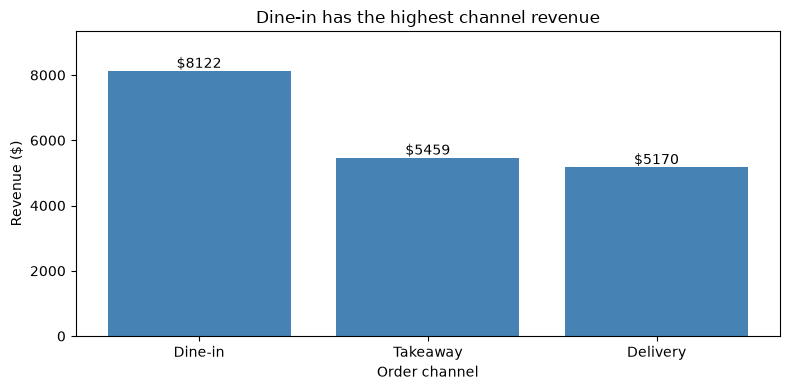

          revenue  orders  revenue_share_pct
channel                                     
Dine-in    8122.0     661              43.32
Takeaway   5459.0     465              29.11
Delivery   5170.0     374              27.57


In [8]:
# ارسم مقارنة إيرادات القنوات.
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(channel_kpis.index, channel_kpis["revenue"], color="steelblue")
ax.set_title("Dine-in has the highest channel revenue")
ax.set_xlabel("Order channel")
ax.set_ylabel("Revenue ($)")
ax.set_ylim(0, channel_kpis["revenue"].max() * 1.15)
ax.bar_label(bars, fmt="$%.0f")
plt.tight_layout()
plt.show()
print(channel_kpis.round(2).to_string())


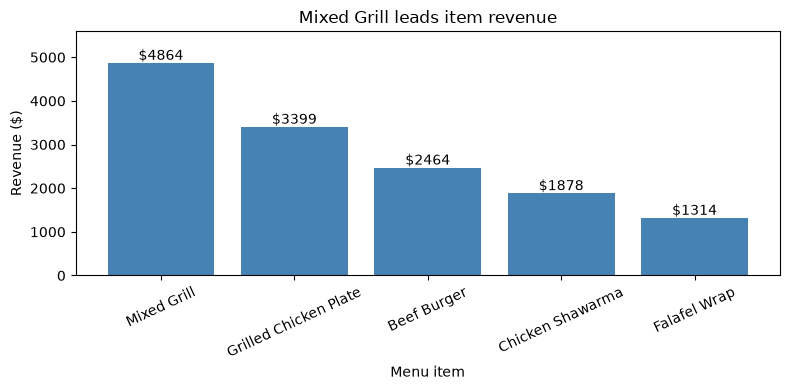

                       revenue  quantity
item                                    
Mixed Grill             4864.0       304
Grilled Chicken Plate   3399.0       309
Beef Burger             2464.0       308
Chicken Shawarma        1878.5       289
Falafel Wrap            1314.0       292


In [9]:
# ارسم أعلى خمسة أصناف من حيث الإيراد.
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(top_items.index, top_items["revenue"], color="steelblue")
ax.set_title("Mixed Grill leads item revenue")
ax.set_xlabel("Menu item")
ax.set_ylabel("Revenue ($)")
ax.tick_params(axis="x", rotation=25)
ax.set_ylim(0, top_items["revenue"].max() * 1.15)
ax.bar_label(bars, fmt="$%.0f")
plt.tight_layout()
plt.show()
print(top_items.round(2).to_string())


<div dir="rtl">

## الخطوة 4: رضا العملاء (س5)
**س5:** هل يرتبط وقت التوصيل بتقييم العميل؟
قسّم طلبات التوصيل إلى ثلاث فئات: أقل من 30 دقيقة، من 30 إلى 45، أكثر من 45. ثم احسب عدد الطلبات ومتوسط التقييم لكل فئة.

> هذه مقارنة بين متوسطات، لا تحتاج أي نموذج تعلم آلي. لكنها لا تثبت السبب وحدها.

</div>

In [10]:
# صنّف طلبات التوصيل مع احتساب 30 و45 ضمن الفئة الوسطى.
delivery = clean.loc[clean["channel"].eq("Delivery")].copy()
delivery["delivery_band"] = pd.NA
delivery.loc[delivery["delivery_minutes"].lt(30), "delivery_band"] = "أقل من 30 دقيقة"
delivery.loc[delivery["delivery_minutes"].between(30, 45, inclusive="both"), "delivery_band"] = "من 30 إلى 45 دقيقة"
delivery.loc[delivery["delivery_minutes"].gt(45), "delivery_band"] = "أكثر من 45 دقيقة"
band_order = ["أقل من 30 دقيقة", "من 30 إلى 45 دقيقة", "أكثر من 45 دقيقة"]
delivery["delivery_band"] = pd.Categorical(delivery["delivery_band"], categories=band_order, ordered=True)

# قارن عدد الطلبات ومتوسط التقييم، مع إظهار عدد التقييمات المسجلة.
delivery_summary = delivery.groupby("delivery_band", observed=False).agg(
    orders=("order_id", "nunique"),
    avg_rating=("rating", "mean"),
    ratings_recorded=("rating", "count"),
)
print(delivery_summary.round(2).to_string())
print("\nالنتيجة وصفية ولا تثبت أن مدة التوصيل هي سبب اختلاف التقييم.")


                    orders  avg_rating  ratings_recorded
delivery_band                                           
أقل من 30 دقيقة         69        4.11                61
من 30 إلى 45 دقيقة     200        3.59               185
أكثر من 45 دقيقة       105        2.47                94

النتيجة وصفية ولا تثبت أن مدة التوصيل هي سبب اختلاف التقييم.


<div dir="rtl">

## الخطوة 5: الرؤى والتوصيات (س6)

### ثلاث رؤى
1. **فرع Mall يحقق أعلى إيرادات:** سجّل **$7,933 (42.31%)** من إجمالي الإيرادات، كما يظهر في جدول المؤشرات حسب الفرع (س1).
2. **الطلب يتركز في نهاية الأسبوع وفي المساء:** السبت هو الأكثر ازدحامًا بـ **280 طلبًا**، والجمعة بـ **278**؛ الساعة 20:00 هي الأعلى بـ **220 طلبًا** (جدول س2).
3. **متوسط التقييم أقل في فئة التوصيل الأطول:** متوسط التقييم **4.11** لأقل من 30 دقيقة، و**3.59** من 30 إلى 45 دقيقة، و**2.47** لأكثر من 45 دقيقة (جدول س5). هذه مقارنة وصفية وليست إثباتًا للسببية.

### ثلاث توصيات
1. **حافظوا على أداء Mall وادرسوا ما يمكن تعميمه:** تابعوا الإيراد ومتوسط قيمة الطلب شهريًا وقارنوهما بالفروع الأخرى؛ خط الأساس لإيراد Mall هو **$7,933** (جدول س1).
2. **راجعوا توزيع التغطية في أوقات الذروة:** افحصوا تغطية يومي السبت والجمعة، خصوصًا الساعة 20:00؛ قيسوا التغير في الطلبات وأوقات الخدمة بعد أي تعديل (جدول س2).
3. **راجعوا خطوات التوصيل التي تتزامن مع الأزمنة الأطول:** راقبوا نسبة الطلبات التي تتجاوز 45 دقيقة ومتوسط تقييم كل فئة، مع مقارنة النتائج دوريًا بخط الأساس **2.47** في فئة أكثر من 45 دقيقة (جدول س5). لا تعتبروا ذلك دليلًا على أن التأخير وحده سبب انخفاض التقييم.

### ما لا نعرفه بعد
- لا تتضمن البيانات تكاليف الأصناف أو التشغيل، لذلك لا يمكن استنتاج الربح الصافي من الإيرادات وحدها.
- لا تشرح البيانات أسباب مدة التوصيل أو التقييم؛ كما أن بعض العملاء لم يتركوا تقييمًا.

## سجل التحقق
| ماذا قال الذكاء الاصطناعي | كيف تحققت | النتيجة |
| --- | --- | --- |
| إجمالي الإيرادات $18,751 وعدد الطلبات 1,500 | إجمالي `total` وعدد `order_id` المميزة بعد إزالة التكرار | مطابق |
| Mall يحقق $7,933؛ السبت 280 طلبًا؛ الساعة 20 بها 220 طلبًا | جدولا الفرع والساعة/اليوم بعد التنظيف | مطابق |
| متوسطات التقييم حسب فئات التوصيل 4.11 و3.59 و2.47 | جدول س5، مع استبعاد التقييمات المفقودة من المتوسط | مطابق |

</div>